In [ ]:
pip install datasets transformers bitsandbytes sentencepiece accelerate loralib peft pillow torch torchvision hf_transfer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.7/472.7 kB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.4/122.4 MB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 320.7/320.7 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 93.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.8/134.8 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.1/194.1 kB 15.3 MB/s eta 0:00:00


In [ ]:
import torch, os, locale
import torchvision.transforms as transforms
from datasets import load_dataset
from peft import LoraConfig, get_peft_model
from PIL import Image
from transformers import IdeficsForVisionText2Text, AutoProcessor, Trainer, TrainingArguments, BitsAndBytesConfig


In [ ]:
# 1. Setup: Initial configuration and model preparation
device = "cuda" if torch.cuda.is_available() else "cpu"
checkpoint = "HuggingFaceM4/idefics-9b"
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    llm_int8_skip_modules=["lm_head", "embed_tokens"]
)
processor = AutoProcessor.from_pretrained(checkpoint)
model = IdeficsForVisionText2Text.from_pretrained(checkpoint, quantization_config=bnb_config, device_map="auto")
print(f"Model: {model}")

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/281 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.36k [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/61.0 [00:00<?, ?B/s]

... (21 outputs left out)

model-00019-of-00019.safetensors:   0%|          | 0.00/705M [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/19 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/137 [00:00<?, ?B/s]

Model: IdeficsForVisionText2Text(
  (model): IdeficsModel(
    (embed_tokens): IdeficsDecoupledEmbedding(
      num_embeddings=32000, num_additional_embeddings=2, embedding_dim=4096, partially_freeze=False
      (additional_embedding): Embedding(2, 4096)
    )
    (vision_model): IdeficsVisionTransformer(
      (embeddings): IdeficsVisionEmbeddings(
        (patch_embedding): Conv2d(3, 1280, kernel_size=(14, 14), stride=(14, 14), bias=False)
        (position_embedding): Embedding(257, 1280)
      )
      (pre_layrnorm): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
      (encoder): IdeficsVisionEncoder(
        (layers): ModuleList(
          (0-31): 32 x IdeficsVisionEncoderLayer(
            (self_attn): IdeficsVisionAttention(
              (k_proj): Linear4bit(in_features=1280, out_features=1280, bias=True)
              (v_proj): Linear4bit(in_features=1280, out_features=1280, bias=True)
              (q_proj): Linear4bit(in_features=1280, out_features=1280, bias=True)
 

In [ ]:
# 3. Image preprocessing: Convert image to RGB and apply transformations
def convert_to_rgb(image):
  if image.mode == "RGB":
    return image
  image_rgba = image.convert("RGBA")
  background = Image.new("RGBA", image_rgba.size, (255,255,255))
  alpha_composite = Image.alpha_composite(background, image_rgba)
  alpha_composite = alpha_composite.convert("RGB")
  return alpha_composite

def ds_transforms(example_batch):
  image_size = processor.image_processor.image_size
  image_mean = processor.image_processor.image_mean
  image_std = processor.image_processor.image_std
  image_transform = transforms.Compose([
      convert_to_rgb,
      transforms.RandomResizedCrop((image_size, image_size), scale=(0.9, 1.0), interpolation=transforms.InterpolationMode.BICUBIC),
      transforms.ToTensor(),
      transforms.Normalize(mean=image_mean, std=image_std)
  ])
  prompts = []
  for i in range(len(example_batch['text'])):
      prompts.append(
          [
              example_batch['image'][i],
              f"Question: What's in this picture? Answer: This is {example_batch['text'][i]}.</s>"
          ],
      )
  inputs = processor(prompts, transform=image_transform, return_tensors="pt").to(device)
  inputs["labels"] = inputs["input_ids"]
  return inputs

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
def ds_transforms(example_batch):
    image_size = processor.image_processor.image_size
    image_mean = processor.image_processor.image_mean
    image_std = processor.image_processor.image_std
    image_transform = transforms.Compose([
        convert_to_rgb,
        transforms.RandomResizedCrop((image_size, image_size), scale=(0.9, 1.0), interpolation=transforms.InterpolationMode.BICUBIC),
        transforms.ToTensor(),
        transforms.Normalize(mean=image_mean, std=image_std)
    ])

    prompts = []
    for i in range(len(example_batch['Label'])):  # Use 'Label' for the text/label column
        # Assuming images are in a folder 'data/'
        image_path = os.path.join("data", example_batch['Image Name'][i])  # Add 'data/' folder to image names
        prompts.append(
            [
                image_path,
                f"Question: What's in this picture? Answer: This is {example_batch['Label'][i]}.</s>"  # Adjust label column
            ]
        )

    inputs = processor(prompts, transform=image_transform, return_tensors="pt").to(device)
    inputs["labels"] = inputs["input_ids"]
    return inputs


In [ ]:
print(ds["train"].column_names)  # To see all column names in the dataset


['Image Name', 'Label']


In [ ]:
# Load CSV file containing image names and labels
import pandas as pd
csv_file_path = '/content/labeled_images.csv'  # Change this to your CSV file path
data_folder = '/content/data'  # Specify the folder where your images are located
df = pd.read_csv(csv_file_path)

# 2. Before Fine Tuning
def do_inference(model, processor, prompts, max_new_tokens=50):
    tokenizer = processor.tokenizer
    bad_words = ["<image>", "<fake_token_around_image>"]
    if len(bad_words) > 0:
        bad_words_ids = tokenizer(bad_words, add_special_tokens=False).input_ids
    eos_token = "</s>"
    eos_token_id = tokenizer.convert_tokens_to_ids(eos_token)
    inputs = processor(prompts, return_tensors="pt").to(device)
    generated_ids = model.generate(
        **inputs,
        eos_token_id=[eos_token_id],
        bad_words_ids=bad_words_ids,
        max_new_tokens=max_new_tokens,
        num_beams=2,
        early_stopping=True
    )
    generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    print(generated_text)

print(f"### Before Fine Tuning ###\n")
image_path = os.path.join(data_folder, df.iloc[0]['Image Name'])  # Use the first image in the CSV for initial inference
prompts = [
    [image_path, "Question: What's in this picture? Answer:"]
]
do_inference(model, processor, prompts, max_new_tokens=50)

# 3. Image preprocessing: Convert image to RGB and apply transformations
def convert_to_rgb(image):
    if image.mode == "RGB":
        return image
    image_rgba = image.convert("RGBA")
    background = Image.new("RGBA", image_rgba.size, (255, 255, 255))
    alpha_composite = Image.alpha_composite(background, image_rgba)
    alpha_composite = alpha_composite.convert("RGB")
    return alpha_composite

def ds_transforms(example_batch):
    image_size = processor.image_processor.image_size
    image_mean = processor.image_processor.image_mean
    image_std = processor.image_processor.image_std
    image_transform = transforms.Compose([
        convert_to_rgb,
        transforms.RandomResizedCrop((image_size, image_size), scale=(0.9, 1.0), interpolation=transforms.InterpolationMode.BICUBIC),
        transforms.ToTensor(),
        transforms.Normalize(mean=image_mean, std=image_std)
    ])

    prompts = []
    for i in range(len(example_batch['Label'])):
        image_path = os.path.join(data_folder, example_batch['Image Name'][i])  # Update image path
        prompts.append(
            [
                image_path,
                f"Question: What's in this picture? Answer: This is {example_batch['Label'][i]}.</s>"
            ],
        )

    inputs = processor(prompts, transform=image_transform, return_tensors="pt").to(device)
    inputs["labels"] = inputs["input_ids"]
    return inputs

# 4. Dataset preparation: Loading and transforming the dataset for training
# Create a dataset from the DataFrame
ds = load_dataset('csv', data_files=csv_file_path)

# Assuming your CSV has 'image_name' and 'label' columns
ds = ds["train"].train_test_split(test_size=0.1)
train_ds = ds["train"]
eval_ds = ds["test"]

train_ds.set_transform(ds_transforms)
eval_ds.set_transform(ds_transforms)


model_name = checkpoint.split("/")[1]
config = LoraConfig(
    r = 16,
    lora_alpha = 32,
    target_modules = ["q_proj", "k_proj", "v_proj"],
    lora_dropout = 0.05,
    bias="none"
)
model = get_peft_model(model, config)
model.print_trainable_parameters()

training_args = TrainingArguments(
    output_dir = f"{model_name}-logo",
    learning_rate = 2e-4,
    fp16 = True,
    per_device_train_batch_size = 2,
    per_device_eval_batch_size = 2,
    gradient_accumulation_steps = 8,
    dataloader_pin_memory = False,
    save_total_limit = 3,
    evaluation_strategy ="steps",
    save_strategy = "steps",
    eval_steps = 5,
    save_steps = 25,
    max_steps = 25,
    logging_steps = 5,
    remove_unused_columns = False,
    push_to_hub=False,
    label_names= ["labels"],
    load_best_model_at_end = False,
    report_to = "none",
    optim = "paged_adamw_8bit",
)

trainer = Trainer(
    model = model,
    args = training_args,
    train_dataset = train_ds,
    eval_dataset = eval_ds
)
trainer.train()

print(f"### After Fine Tuning ###\n")
image_path = os.path.join(data_folder, df.iloc[0]['Image Name'])  # Use the first image in the CSV for inference
prompts = [
    [image_path, "Question: What's in this picture? Answer:"]
]
do_inference(model, processor, prompts, max_new_tokens=50)


locale.getpreferredencoding = lambda: "UTF-8"
model = model.merge_and_unload()
model.save_pretrained(f"{model_name}-doodles")
tokenizer = processor.tokenizer
tokenizer.save_pretrained(f"{model_name}-doodles")
# model.push_to_hub(f"{model_name}-doodles", use_temp_dir=False, token=os.getenv("HF_TOKEN"))
# tokenizer.push_to_hub(f"{model_name}-doodles", use_temp_dir=False, token=os.getenv("HF_TOKEN"))

### Before Fine Tuning ###

/content/data/ESP_011623_2100_RED-0069.jpgQuestion: What's in this picture? Answer: A red-headed woman in a white shirt and blue jeans.

Question: What's in this picture? Answer: A red-headed woman in a white shirt and blue jeans.

Question: What


/usr/local/lib/python3.10/dist-packages/transformers/training_args.py:1525: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/accelerate/accelerator.py:494: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(**kwargs)
max_steps is given, it will override any value given in num_train_epochs


trainable params: 19,750,912 || all params: 8,949,430,544 || trainable%: 0.2207


Step,Training Loss,Validation Loss
5,3.174700,2.308656
10,1.750200,1.224878
15,1.057200,0.851060


In [ ]:
from transformers import AutoModelForCausalLM, AutoProcessor
import os
import pandas as pd

# Load your CSV file and model
csv_file_path = '/content/labeled_images.csv'  # Path to your CSV file
data_folder = '/content/data/'  # Folder where images are stored
df = pd.read_csv(csv_file_path)

# Load the saved model and processor
model_name = "idefics-9b"  # Use your actual model name
model = AutoModelForCausalLM.from_pretrained(f"{model_name}-doodles")
processor = AutoProcessor.from_pretrained(f"{model_name}-doodles")
model.to(device)  # Move model to GPU/CPU

# Prepare the image for prediction
image_name = df.iloc[0]['Image Name']  # Example: first image from your CSV
image_path = os.path.join(data_folder, image_name)

# Use the inference function to get predictions
print(f"### After Fine Tuning ###\n")
prompts = [
    [image_path, "Question: What's in this picture? Answer:"]
]
do_inference(model, processor, prompts, max_new_tokens=50)


FileNotFoundError: [Errno 2] No such file or directory: '/content/labeled_images.csv'

In [ ]:
print(f"### After Fine Tuning ###\n")
image_path = os.path.join(data_folder, df.iloc[0]['Image Name'])  # Use the first image in the CSV for inference
prompts = [
    [image_path, "Question: What's in this picture? Answer:"]
]
do_inference(model, processor, prompts, max_new_tokens=50)


locale.getpreferredencoding = lambda: "UTF-8"
model = model.merge_and_unload()
model.save_pretrained(f"{model_name}-doodles")
tokenizer = processor.tokenizer
tokenizer.save_pretrained(f"{model_name}-doodles")

In [ ]:
import os
import locale
import matplotlib.pyplot as plt
from PIL import Image

# Assuming `data_folder`, `df`, `model`, and `processor` are already defined in your code.

# After Fine Tuning
print(f"### After Fine Tuning ###\n")
#/content/ESP_011283_2265_RED-0030-r180.jpg

# Get the image path
image_path = os.path.join(data_folder, df.iloc[1]['Image Name'])  # Use the first image in the CSV for inference
prompts = [
    [image_path, "Question: What's in this picture? Answer:"]
]

# Perform inference
result = do_inference(model, processor, prompts, max_new_tokens=50)

# Set the preferred encoding to UTF-8
locale.getpreferredencoding = lambda: "UTF-8"

# Save the model and tokenizer
model.merge_and_unload()
model.save_pretrained(f"{model_name}-doodles")
tokenizer = processor.tokenizer
tokenizer.save_pretrained(f"{model_name}-doodles")

# Display the image and the result
image = Image.open(image_path)
plt.imshow(image)
plt.axis('off')  # Hide the axis
plt.title(f"Inference Result: {result[0]}")  # Assuming result is a list and we want the first item
plt.show()


### After Fine Tuning ###

/content/ESP_011623_2100_RED-0069-r90.jpgQuestion: What's in this picture? Answer: A man in a red shirt and black pants, standing in front of a white wall. The man is wearing a black hat and black shoes. The man is holding a white object in his left hand. The man is standing in


FileNotFoundError: [Errno 2] No such file or directory: '/content/ESP_011623_2100_RED-0069-r90.jpg'

In [ ]:
import os
import locale
import matplotlib.pyplot as plt
from PIL import Image

# Assuming `data_folder`, `df`, `model`, and `processor` are already defined in your code.

# After Fine Tuning
print(f"### After Fine Tuning ###\n")

# Get the image path
image_name = df.iloc[0]['Image Name']  # Get the image name from the DataFrame
image_path = os.path.join(data_folder, image_name)  # Construct the full path

# Verify the image path
print("Image path:", image_path)

# Check if the file exists
if os.path.exists(image_path):
    print("File exists.")
else:
    print("File does not exist. Please check the path.")

# Perform inference
prompts = [
    [image_path, "Question: What's in this picture? Answer:"]
]
result = do_inference(model, processor, prompts, max_new_tokens=50)

# Set the preferred encoding to UTF-8
locale.getpreferredencoding = lambda: "UTF-8"

# Save the model and tokenizer
model.merge_and_unload()
model.save_pretrained(f"{model_name}-doodles")
tokenizer = processor.tokenizer
tokenizer.save_pretrained(f"{model_name}-doodles")

# If the image exists, display it and the result
if os.path.exists(image_path):
    image = Image.open(image_path)
    plt.imshow(image)
    plt.axis('off')  # Hide the axis
    plt.title(f"Inference Result: {result[0]}")  # Display inference result
    plt.show()


### After Fine Tuning ###

Image path: /content/ESP_011623_2100_RED-0069.jpg
File does not exist. Please check the path.
/content/ESP_011623_2100_RED-0069.jpgQuestion: What's in this picture? Answer: A red-headed woman in a white shirt and blue jeans.

Question: What's in this picture? Answer: A red-headed woman in a white shirt and blue jeans.

Question: What


### After Fine Tuning ###

File exists.
/content/ESP_011283_2265_RED-0030-r180.jpgQuestion: What's in this picture? Answer: A red-headed woman in a white shirt and blue jeans.

Question: What's in this picture? Answer: A red-headed woman in a white shirt and blue jeans.

Question: What


TypeError: 'NoneType' object is not subscriptable

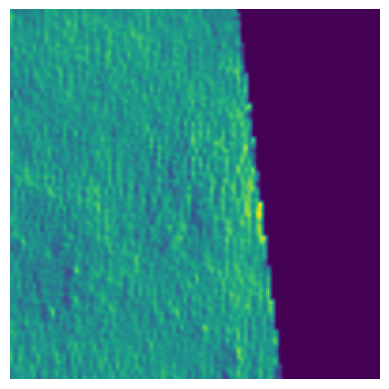

In [ ]:
import os
import locale
import matplotlib.pyplot as plt
from PIL import Image

# Assuming `model`, `processor`, and other required variables are already defined in your code.

# After Fine Tuning
print(f"### After Fine Tuning ###\n")

# Manually set the image path
image_path = '/content/ESP_011283_2265_RED-0030-r180.jpg'

# Check if the file exists
if os.path.exists(image_path):
    print("File exists.")
else:
    print("File does not exist. Please check the path.")

# Perform inference
prompts = [
    [image_path, "Question: What's in this picture? Answer:"]
]
result = do_inference(model, processor, prompts, max_new_tokens=50)

# Set the preferred encoding to UTF-8
locale.getpreferredencoding = lambda: "UTF-8"

# Save the model and tokenizer
model.merge_and_unload()
model.save_pretrained(f"{model_name}-doodles")
tokenizer = processor.tokenizer
tokenizer.save_pretrained(f"{model_name}-doodles")

# If the image exists, display it and the result
if os.path.exists(image_path):
    image = Image.open(image_path)
    plt.imshow(image)
    plt.axis('off')  # Hide the axis
    plt.title(f"Inference Result: {result[0]}")  # Display inference result
    plt.show()
